# **Australian Household Financial Stress Index (2022–2026)**

## Project Description

Between May 2022 and November 2023, the Reserve Bank of Australia executed the most aggressive monetary tightening cycle in its modern history — 13 rate hikes across 18 months, lifting the cash rate from a historic low of 0.10% to 4.35%. The cycle was not linear: four consecutive 50 basis point hikes landed between June and September 2022 as the RBA scrambled to contain inflation that had reached 7.8%, followed by a slower series of 25 basis point moves, two brief pauses, and a final hike in November 2023. Simultaneously, Australian households faced accelerating cost-of-living pressures across housing, utilities, and insurance, while the COVID-era savings buffer accumulated during 2020–2021 steadily eroded.

These forces did not affect all households equally. A mortgage-holding single parent in NSW faced a fundamentally different financial reality than an outright homeowner couple in ACT — yet aggregate economic reporting rarely surfaces these distinctions with precision.

This project builds a **Financial Stress Score (0–100)** — a composite index engineered from four weighted components: housing-to-income ratio, savings rate, debt load, and expense pressure — applied across 5,000 synthetic Australian households observed quarterly from Q1 2022 to Q4 2026. The analysis then projects the national and segment-level stress trajectories forward to 2029 using NumPy polynomial fitting.

> **Important:** The dataset used in this project is entirely synthetic — no real household financial records were used. Every observation was generated programmatically, with distributions, income ranges, housing costs, and macro trends calibrated to mirror real Australian market conditions as closely as possible: ABS income quintiles by state, the RBA tightening trajectory, and state-level housing cost differentials. This is not a study of what happened — it is an attempt to model what *could* have happened, using realistic parameters. Figures should not be cited as representative of actual Australian household statistics.

---

## Scope

- **EDA** across 100,000 observations — distributions, trends, and segment comparisons by state, household type, age bracket, and employment type
- **Component analysis** — isolating the individual drivers of financial stress and quantifying their relative contribution via correlation and sensitivity analysis
- **Predictive projection** — extending the national and segment-level stress trajectories to 2029 using NumPy polynomial fitting (`np.polyfit`)
- **Business recommendations** — translating analytical findings into a prioritisation framework for financial services intervention

The entire analysis is built on Pandas and NumPy. No machine learning libraries are used — every output is interpretable and traceable back to its inputs.

---

# 0. Setup & Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec  
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
# from ydata_profiling import ProfileReport

---

# 1. Data Quality & Structural Overview



## Dataset Completeness & Shape





**Business Question:** Does the dataset contain the expected number of rows, columns, and observations per
household and quarter? Are there any missing values, duplicates or structural anomalies?

In [2]:
df = pd.read_csv(r"C:\Users\Asus\Aus Household EDA\data\aus_household_financial_stress.csv")

In [3]:
#profile = ProfileReport(df, title='EDA Analysis Report', explorative=True)

# profile.to_file('analysis_report.html') --> full data overview: 'analysis_report.html'

In [4]:
# raw data memory usage: 

df.info(memory_usage=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 21 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   household_id             100000 non-null  object 
 1   quarter                  100000 non-null  object 
 2   year                     100000 non-null  int64  
 3   quarter_num              100000 non-null  int64  
 4   state                    100000 non-null  object 
 5   household_type           100000 non-null  object 
 6   age_bracket              100000 non-null  object 
 7   employment_type          100000 non-null  object 
 8   n_income_earners         100000 non-null  int64  
 9   housing_status           100000 non-null  object 
 10  gross_annual_income      100000 non-null  float64
 11  monthly_housing_cost     100000 non-null  float64
 12  monthly_utilities        100000 non-null  float64
 13  monthly_insurance        100000 non-null  float64
 14  savin

In [5]:
# clean data memory usage: 

df = df.astype({'household_id': 'string', 'quarter': 'string', 'state': 'category', 
                'household_type': 'category', 'age_bracket': 'category', 'employment_type': 'category', 
                'housing_status': 'category', 'quarter_num': 'int8', 'n_income_earners': 'int16', 'financial_stress_score': 'float64', 'year' : 'int32'})


df.info(memory_usage=True)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 21 columns):
 #   Column                   Non-Null Count   Dtype   
---  ------                   --------------   -----   
 0   household_id             100000 non-null  string  
 1   quarter                  100000 non-null  string  
 2   year                     100000 non-null  int32   
 3   quarter_num              100000 non-null  int8    
 4   state                    100000 non-null  category
 5   household_type           100000 non-null  category
 6   age_bracket              100000 non-null  category
 7   employment_type          100000 non-null  category
 8   n_income_earners         100000 non-null  int16   
 9   housing_status           100000 non-null  category
 10  gross_annual_income      100000 non-null  float64 
 11  monthly_housing_cost     100000 non-null  float64 
 12  monthly_utilities        100000 non-null  float64 
 13  monthly_insurance        100000 non-null  flo

In [6]:
df_check_quarters = df.groupby(['household_id']).agg(number_of_quarters = ('year','count'))

#filter only the household_ids whose number of quarters is not 20
df_check_quarters[df_check_quarters['number_of_quarters'] != 20]

,number_of_quarters
household_id,


In [7]:
(df['state'].value_counts(normalize=True) * 100).round(2).astype('string') + '%'

state
NSW     32.4%
VIC    25.38%
QLD    20.34%
WA     11.14%
SA       6.7%
TAS      2.1%
ACT     1.18%
NT      0.76%
Name: proportion, dtype: string

In [8]:
(df['household_type'].value_counts(normalize=True) * 100).round(2).astype('string') + '%'

household_type
Couple           31.88%
Family           28.48%
Single           25.28%
Single Parent    14.36%
Name: proportion, dtype: string

In [9]:
df.head()

,household_id,quarter,year,quarter_num,state,household_type,age_bracket,employment_type,n_income_earners,housing_status,...,monthly_housing_cost,monthly_utilities,monthly_insurance,savings_balance,total_debt,savings_rate_pct,housing_to_income_ratio,expense_pressure_ratio,debt_to_income_ratio,financial_stress_score
0,HH00001,2022Q1,2022,1,VIC,Couple,35-44,Full-time,2,Owner Outright,...,0.00,430.09,165.09,41175.17,52965.33,80.00,0.0000,0.0528,0.3915,6.68
1,HH00002,2022Q1,2022,1,SA,Couple,35-44,Part-time,2,Owner with Mortgage,...,2727.35,365.70,191.74,66383.50,58598.84,19.69,0.6668,0.8031,1.1938,58.94
2,HH00003,2022Q1,2022,1,QLD,Single Parent,25-34,Part-time,1,Owner with Mortgage,...,3038.83,257.40,237.22,44749.59,47620.62,-7.62,0.9255,1.0762,1.2087,75.78
3,HH00004,2022Q1,2022,1,QLD,Couple,45-54,Full-time,2,Renter,...,1710.84,394.37,181.76,74596.69,81601.57,74.94,0.1875,0.2506,0.7453,11.82
4,HH00005,2022Q1,2022,1,NSW,Single Parent,35-44,Full-time,1,Renter,...,2010.68,435.70,164.37,18230.32,10477.80,61.66,0.2953,0.3834,0.1282,22.73




## Income Distribution by State & Household Type


*Note: property owners ('Owner Outright') are excluded from this analysis since their null housing cost would deflate the real economic stress.*


**Business Question:** How is gross annual income distributed across states and household types? Are the
distributions consistent with known ABS benchmarks?

*Note: NSW, VIC, WA and ACT selected for their structurally distinct housing cost profiles. Remaining states cluster within a similar range and are excluded for visual clarity.*


In [10]:
df_no_owner = df[df['housing_status'] != 'Owner Outright'].copy()
df_no_owner['housing_status'] = df_no_owner['housing_status'].cat.remove_unused_categories()

df_focus_state = df_no_owner[df_no_owner['state'].isin(["NSW", "VIC", "WA", "QLD"])].copy() 
df_focus_state['state'] = df_focus_state['state'].cat.remove_unused_categories() 

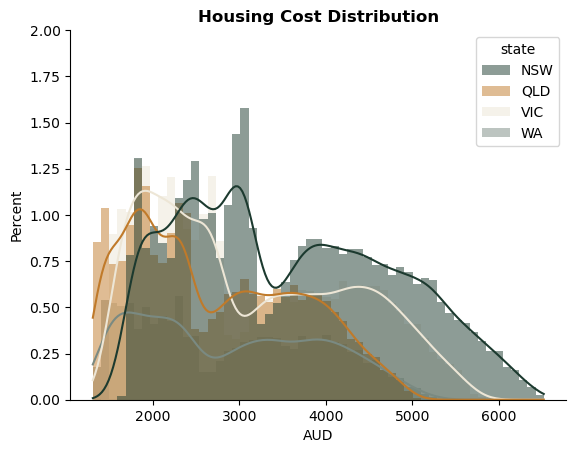

In [11]:
fig, ax = plt.subplots()

ax.set_title('Housing Cost Distribution', fontweight='bold')

sns.histplot(
             data= df_focus_state, 
             x='monthly_housing_cost', 
             hue= 'state', 
             kde=True, 
             stat='percent', 
             linewidth= 0, 
             palette=['#1C3A2F', '#C07A2A', '#EDE6D6', '#7A8A82']
)

ax.set_ylim(0, 2)
ax.set_xlabel('AUD')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False); 


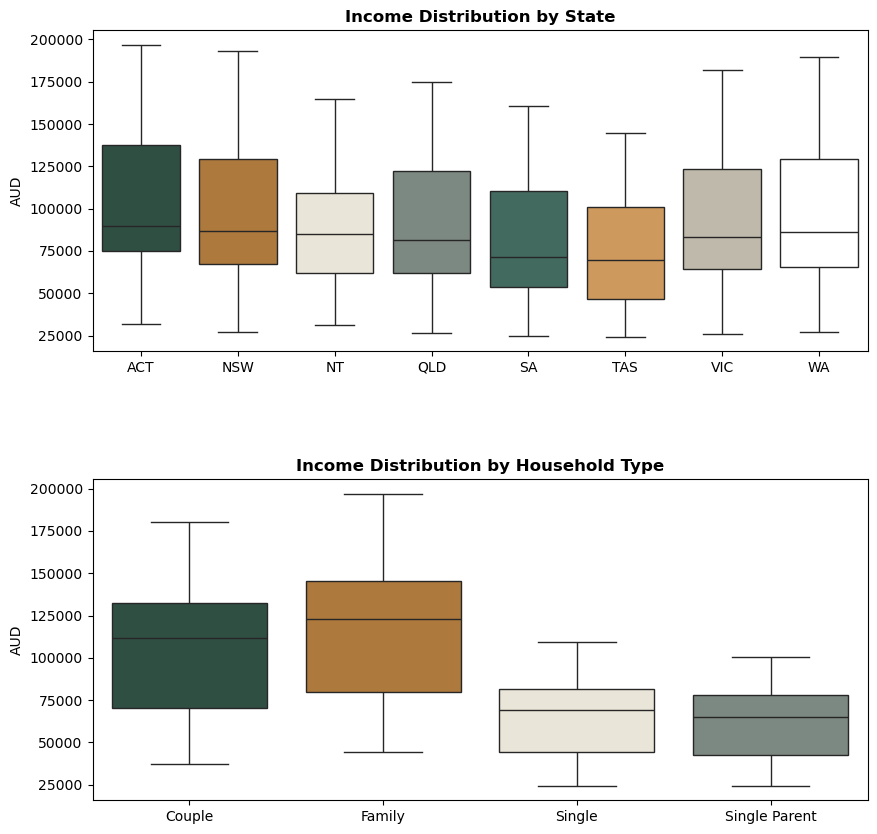

In [12]:
fig, ax = plt.subplots(2,1, figsize=(10, 10))

ax[0].set_title('Income Distribution by State', fontweight='bold')

sns.boxplot(
            data= df_no_owner, 
            x='state', 
            y='gross_annual_income', 
            hue= 'state', 
            legend= False, 
            palette=['#2B5444', '#C07A2A', '#EDE6D6', '#7A8A82', '#3D7060', '#E09A4A', '#C2BAA8', '#FFFFFF'],
            ax=ax[0]  
)

ax[0].set_xlabel('')
ax[0].set_ylabel('AUD')



plt.subplots_adjust(hspace= .4)



ax[1].set_title('Income Distribution by Household Type', fontweight='bold')

sns.boxplot(
            data= df_no_owner, 
            x='household_type', 
            y='gross_annual_income', 
            hue= 'household_type', 
            legend= False, 
            palette=['#2B5444', '#C07A2A', '#EDE6D6', '#7A8A82'],
            ax=ax[1] 
)

ax[1].set_xlabel('')
ax[1].set_ylabel('AUD'); 





## Housing Cost Distribution & Status Breakdown


**Business Question:** How do monthly housing costs vary by state, housing status, and over time? Does the
data reflect known Sydney and Melbourne housing cost premiums?


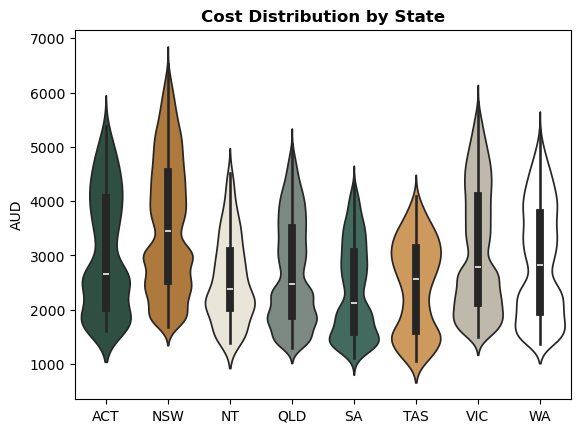

In [13]:
fig, ax = plt.subplots()

ax.set_title('Cost Distribution by State', fontweight='bold')

sns.violinplot(
               data= df_no_owner, 
               x= 'state', 
               y='monthly_housing_cost', 
               palette=['#2B5444', '#C07A2A', '#EDE6D6', '#7A8A82', '#3D7060', '#E09A4A', '#C2BAA8', '#FFFFFF'], 
               hue= 'state', 
               legend= False
)

ax.set_xlabel('')
ax.set_ylabel('AUD'); 

In [14]:
state_average_cost = (
    df_no_owner.groupby('state', observed=True).agg({'monthly_housing_cost':'mean'})
)

state_average_cost = state_average_cost.sort_values('monthly_housing_cost', ascending=False)


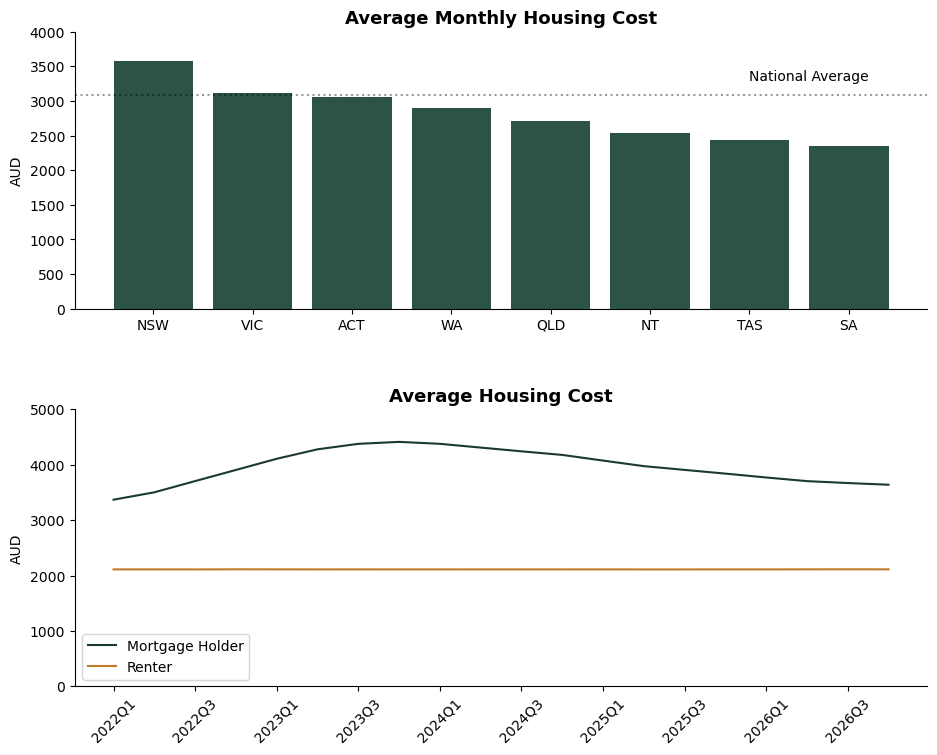

In [15]:
plt.rc('axes.spines', right = False, top = False)
plt.rc('axes', titlesize = 13)
# dict of rc parameters:  plt.rcParams.keys()

fig = plt.figure(figsize=(11,8.5))
gs = gridspec.GridSpec(nrows= 9,ncols= 8)

ax1 = fig.add_subplot(gs[:4, :])
ax2 = fig.add_subplot(gs[5:, :])



ax1.set_title('Average Monthly Housing Cost', fontweight='bold')
ax1.bar(state_average_cost.index, state_average_cost['monthly_housing_cost'], color = '#2B5444')

ax1.axhline(df_no_owner['monthly_housing_cost'].mean(), color='000000', alpha= .4, ls='dotted')


ax1.text(
        6, 3300, 'National Average', 
        fontsize=10,
        bbox=dict(facecolor='white', edgecolor='white')
)




ax1.set_ylabel('AUD')
ax1.set_ylim(0, 4000)

plt.subplots_adjust(hspace= .5)





housing_status_average_cost = (df_no_owner.groupby(['quarter', 'housing_status'], observed=True).agg(Avg_monthly_cost = ('monthly_housing_cost', 'mean'))
                                                                                                    ).unstack('housing_status').droplevel(0, axis=1)
housing_status_average_cost = housing_status_average_cost.sort_values('quarter', ascending=True)


ax2.set_title('Average Housing Cost', fontweight='bold')

ax2.plot(housing_status_average_cost.index, 
        housing_status_average_cost['Owner with Mortgage'], 
        color = '#1C3A2F', 
        label = 'Mortgage Holder')

ax2.plot(housing_status_average_cost.index, 
        housing_status_average_cost['Renter'], 
        color = '#C07A2A', 
        label = 'Renter') 

ax2.set_ylabel('AUD')

ax2.set_ylim(0, 5000)

fig.legend(bbox_to_anchor = (.29, .18))


ax2.set_xticks(housing_status_average_cost.index[::2])
plt.xticks(rotation=45); 




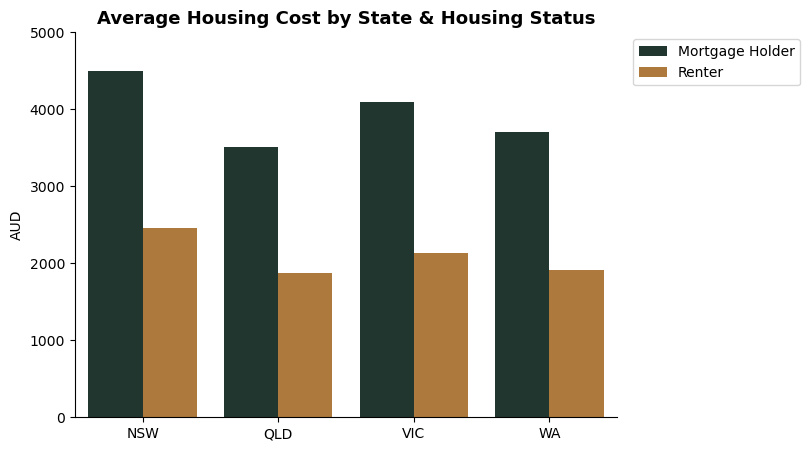

In [16]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.set_title('Average Housing Cost by State & Housing Status', fontweight = 'bold')

sns.barplot(
            data= df_focus_state,
            x= 'state', 
            y= 'monthly_housing_cost', 
            hue= 'housing_status', 
            errorbar= None,
            palette= ['#1C3A2F' ,'#C07A2A'], 
            
)

ax.set_ylim(0,5000)
ax.set_ylabel('AUD')

ax.set_xlabel('')
ax.legend(labels= ['Mortgage Holder', 'Renter'], bbox_to_anchor = (1.35, 1));

---
# 2. Financial Stress Score — Distribution


## National Stress Score Distribution




**Business Question:** What does the overall distribution of financial stress look like across all households and
time periods? Where does the average Australian household sit on the stress index?

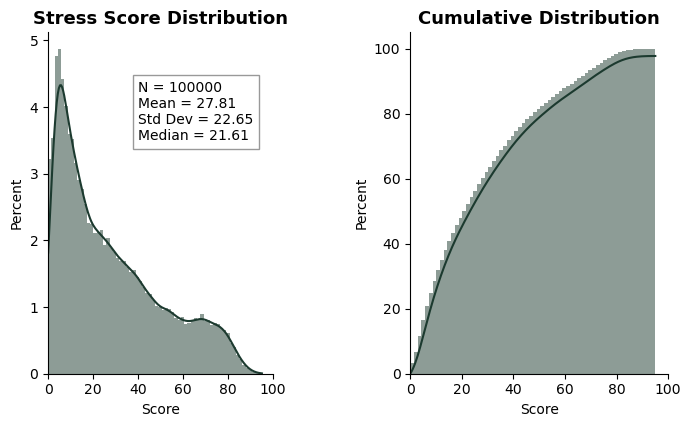

In [17]:
fig = plt.figure(figsize=(8, 5))
gs = gridspec.GridSpec(nrows= 9,ncols= 19)

ax1 = fig.add_subplot(gs[:8, :7])
ax2 = fig.add_subplot(gs[:8, 11:])


ax1.set_title('Stress Score Distribution', fontweight= 'bold')

sns.histplot(
             data= df,
             x= 'financial_stress_score', 
             kde=True,
             stat='percent', 
             linewidth= 0,
             color='#1C3A2F', 
             ax= ax1

)

ax1.set_xlim(0,100)
ax1.set_xlabel('Score')




mean_val = df['financial_stress_score'].mean()
std_val = df['financial_stress_score'].std()
median_val = df['financial_stress_score'].median()
n = df['financial_stress_score'].count()

stats_text = f"N = {n}\nMean = {mean_val:.2f}\nStd Dev = {std_val:.2f}\nMedian = {median_val:.2f}"

ax1.text(
        40, 3.5, stats_text, 
        fontsize=10,
        bbox=dict(facecolor='white', edgecolor='gray', alpha=0.8)
)




ax2.set_title('Cumulative Distribution', fontweight= 'bold')


sns.histplot(
             data= df,
             x= 'financial_stress_score', 
             kde=True,
             stat='percent', 
             linewidth= 0,
             color='#1C3A2F',
             cumulative= True, 
             ax= ax2

)
 
ax2.set_xlim(0,100) 
ax2.set_xlabel('Score') 

ax2.set_ylabel('Percent'); 


 

## Stress Score Trends Over Time (2022–2026)

**Business Question:** How did the national average financial stress score change quarter by quarter? Is the
impact of the RBA rate hike cycle (May 2022 – late 2023) visible in the data?

In [18]:
quarter_stress_score = df.groupby('quarter').agg({'financial_stress_score': 'mean'})

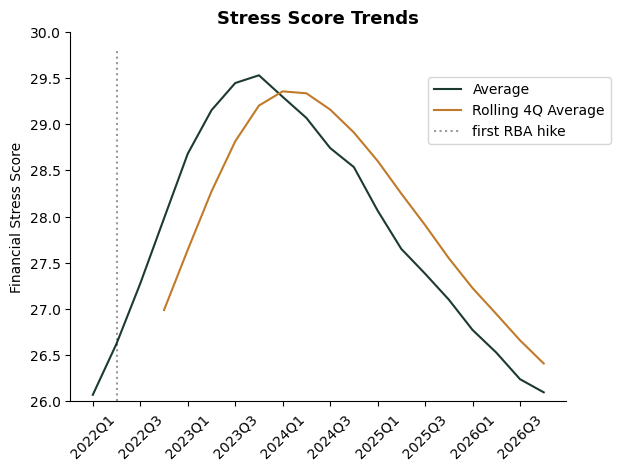

In [19]:
fig, ax = plt.subplots()

ax.set_title('Stress Score Trends', fontweight='bold')

ax.plot(quarter_stress_score.index, 
        quarter_stress_score['financial_stress_score'], 
        color='#1C3A2F', 
        label='Average')

ax.set_ylabel('Financial Stress Score')
ax.set_ylim(26, 30)

ax.plot(quarter_stress_score.index, 
        quarter_stress_score.rolling(4).mean(), 
        color='#C07A2A', 
        label= 'Rolling 4Q Average')


ax.axvline('2022Q2', ymax= .95 , ls='dotted', color='000000', label='first RBA hike', alpha= .4)
 


fig.legend(bbox_to_anchor = (.98, .8))

ax.set_xticks(quarter_stress_score.index[::2])

plt.xticks(rotation=45); 

## Stress Score by State — Heatmap Analysis

**Business Question:** Which states consistently show the highest and lowest average stress scores? How does
the state-level stress pattern evolve over the observation period?

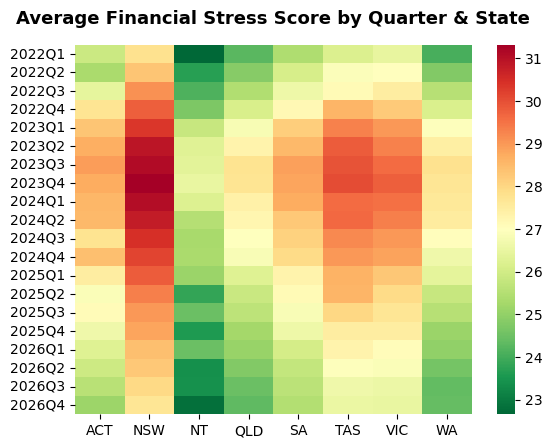

In [20]:
state_stress_pivot = df.pivot_table(
                                    index='state', 
                                    columns='quarter',
                                    values='financial_stress_score', 
                                    aggfunc='mean', 
                                    observed=False
)


sns.heatmap(
            state_stress_pivot.T, 
            cmap='RdYlGn_r'
)

plt.title('Average Financial Stress Score by Quarter & State', fontweight='bold', pad=15)
plt.xlabel("")
plt.ylabel("");  

## Stress Score by Household Type & Age Bracket

**Business Question:** Which household types and age groups carry the highest financial stress burden? Are
single parents or younger households disproportionately affected?

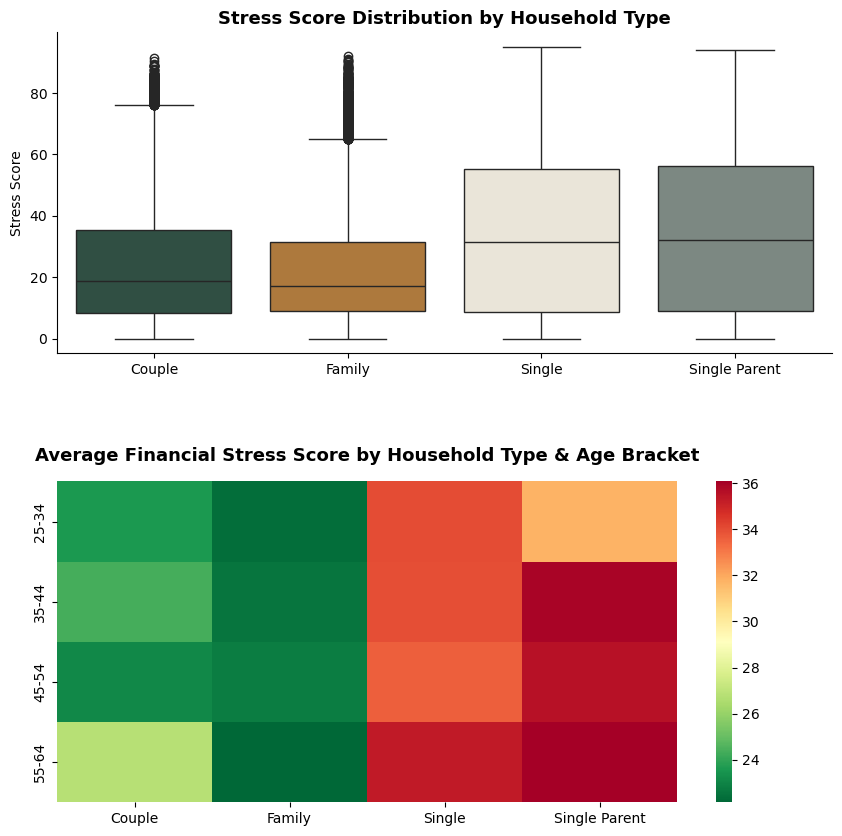

In [21]:
fig, ax = plt.subplots(2, 1, figsize=(10,10))


ax[0].set_title('Stress Score Distribution by Household Type', fontweight='bold')

sns.boxplot(
            data= df, 
            x='household_type', 
            y='financial_stress_score', 
            hue= 'household_type', 
            legend= False, 
            palette=['#2B5444', '#C07A2A', '#EDE6D6', '#7A8A82'],
            ax=ax[0]
)

ax[0].set_xlabel('')
ax[0].set_ylabel('Stress Score')




plt.subplots_adjust(hspace= .4)





age_stress_pivot = df.pivot_table(
                                  index='household_type',
                                  columns='age_bracket', 
                                  values='financial_stress_score', 
                                  aggfunc='mean', 
                                  observed=False
                                  
)


sns.heatmap(
            age_stress_pivot.T, 
            cmap='RdYlGn_r', 
            ax=ax[1]
)

ax[1].set_title('Average Financial Stress Score by Household Type & Age Bracket', fontweight='bold', pad=15)
ax[1].set_xlabel("")
ax[1].set_ylabel("");  
 


## Stress Score by Employment Type

**Business Question:** How does employment stability affect financial stress? Do casual and self-employed
households show materially higher stress than full-time workers?

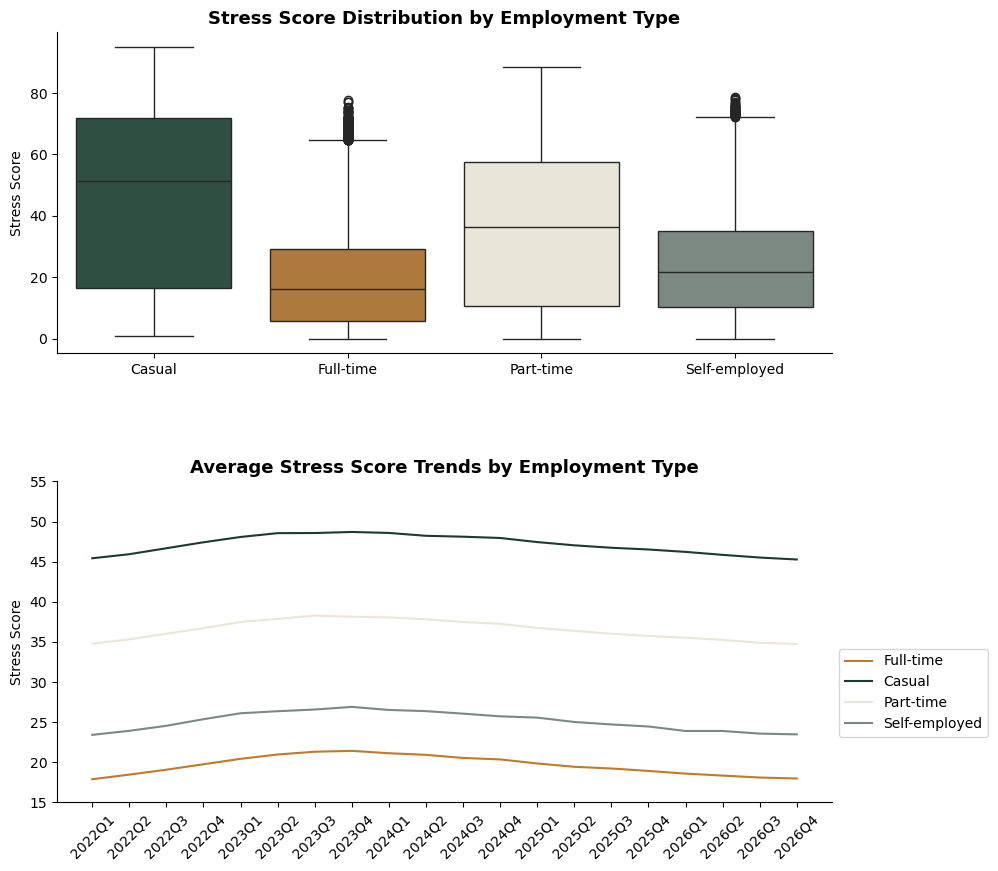

In [22]:
fig, ax = plt.subplots(2,1, figsize=(10,10))

ax[0].set_title('Stress Score Distribution by Employment Type', fontweight='bold')

sns.boxplot(
            data= df, 
            x='employment_type', 
            y='financial_stress_score', 
            hue= 'employment_type', 
            legend= False, 
            palette=['#2B5444', '#C07A2A', '#EDE6D6', '#7A8A82'], 
            ax=ax[0]
)

ax[0].set_xlabel('')
ax[0].set_ylabel('Stress Score')



plt.subplots_adjust(hspace= .4)


ax[1].set_title('Average Stress Score Trends by Employment Type', fontweight='bold')


df_casual_full_stress = df.groupby(['quarter', 'employment_type'], observed = True).agg({'financial_stress_score':'mean'}).unstack('employment_type').droplevel(0, axis=1)

ax[1].plot(
           df_casual_full_stress.index,
           df_casual_full_stress['Full-time'], 
           label= 'Full-time', 
           color= '#C07A2A'
           
)


ax[1].plot(
           df_casual_full_stress.index,
           df_casual_full_stress['Casual'], 
           label= 'Casual',  
           color= '#1C3A2F'
           
)


ax[1].plot(
           df_casual_full_stress.index,
           df_casual_full_stress['Part-time'], 
           label= 'Part-time',  
           color= '#EDE6D6'
           
)



ax[1].plot(
           df_casual_full_stress.index,
           df_casual_full_stress['Self-employed'], 
           label= 'Self-employed',  
           color= '#7A8A82'
           
)



ax[1].legend(bbox_to_anchor = (1, .5))

ax[1].set_ylim(15, 55)
ax[1].set_ylabel('Stress Score')
ax[1].tick_params(axis='x', rotation=45);


---
# 3. Stress Components — Deep Dive


## Housing-to-Income Ratio Trends 

**Business Question:** How has the housing cost burden relative to income changed over time? At what point did
mortgage holders begin spending an unsustainable share of income on housing?

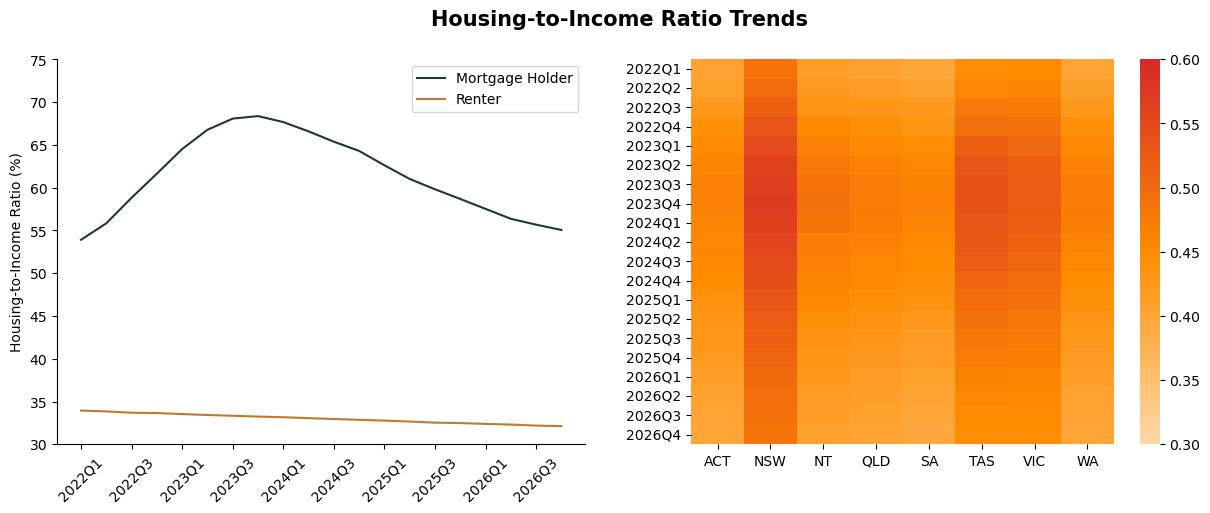

In [23]:
housing_to_income_pivot = df_no_owner.pivot_table(
                                                  index= 'quarter', 
                                                  columns= 'housing_status', 
                                                  values= 'housing_to_income_ratio', 
                                                  aggfunc= 'mean', 
                                                  observed= False
)


fig, ax = plt.subplots(1,2, figsize=(15,5)) 

fig.suptitle('Housing-to-Income Ratio Trends', fontweight='bold', fontsize=15)


ax[0].plot(
        housing_to_income_pivot.index, 
        housing_to_income_pivot['Owner with Mortgage'] * 100,
        color = '#1C3A2F', 
        label = 'Mortgage Holder'     
)


ax[0].plot(
        housing_to_income_pivot.index, 
        housing_to_income_pivot['Renter'] * 100,
        color = '#C07A2A', 
        label = 'Renter'     
)

ax[0].legend(bbox_to_anchor=(1, 1))

ax[0].set_ylabel('Housing-to-Income Ratio (%)')
ax[0].set_ylim(30, 75)

ax[0].set_xticks(housing_to_income_pivot.index[::2])
ax[0].tick_params(axis='x', rotation=45)



plt.subplots_adjust(hspace=.5)



colors = ['#FFD8A8', '#FF8C00', '#D62828']  
danger_cmap = LinearSegmentedColormap.from_list('danger_cmap', colors)

sns.heatmap(
            df_no_owner.groupby(['quarter', 'state'], observed=False).agg({'housing_to_income_ratio': 'mean'}).unstack('state').droplevel(0, axis=1), 
            cmap=danger_cmap, 
            vmin= .3, 
            vmax= .6, 
            ax=ax[1] 
            
)

ax[1].set_xlabel('')
ax[1].set_ylabel(''); 

## Savings Rate Deterioration

**Business Question:** How did household savings rates change across the observation period? Which segments
depleted their COVID-era savings buffer fastest?

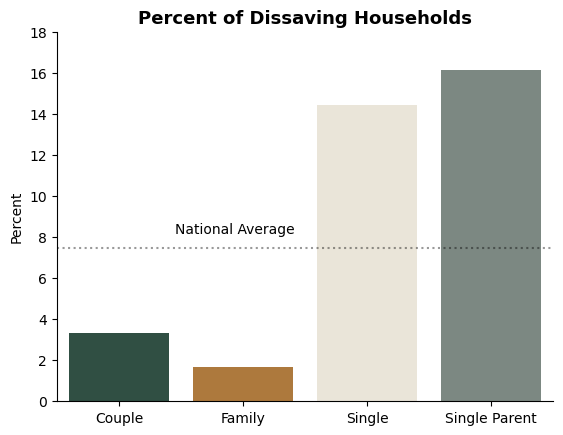

In [24]:
fig, ax = plt.subplots()  

dissaving_df = df.assign(is_dissaving = df['savings_rate_pct'] < 0)


ax.set_title('Percent of Dissaving Households', fontweight='bold')

sns.barplot(
             data= dissaving_df.groupby('household_type', observed = False).agg({'is_dissaving': 'mean'}) * 100, 
             x='household_type', 
             y='is_dissaving', 
             hue='household_type', 
             palette=['#2B5444', '#C07A2A', '#EDE6D6', '#7A8A82']
             
)

ax.axhline(dissaving_df['is_dissaving'].mean() * 100, color='000000', label='National Average', alpha= .4, ls='dotted')

ax.text(
        .45, 8.2, 'National Average', 
        fontsize=10,
        bbox=dict(facecolor='white', edgecolor='white')
)


ax.set_xlabel('')

ax.set_ylabel('Percent')
ax.set_ylim(0,18); 


## Correlation Matrix — Stress Drivers


**Business Question:** Which variables are most strongly correlated with the financial stress score? Are any
components redundant or unexpectedly weakly correlated?

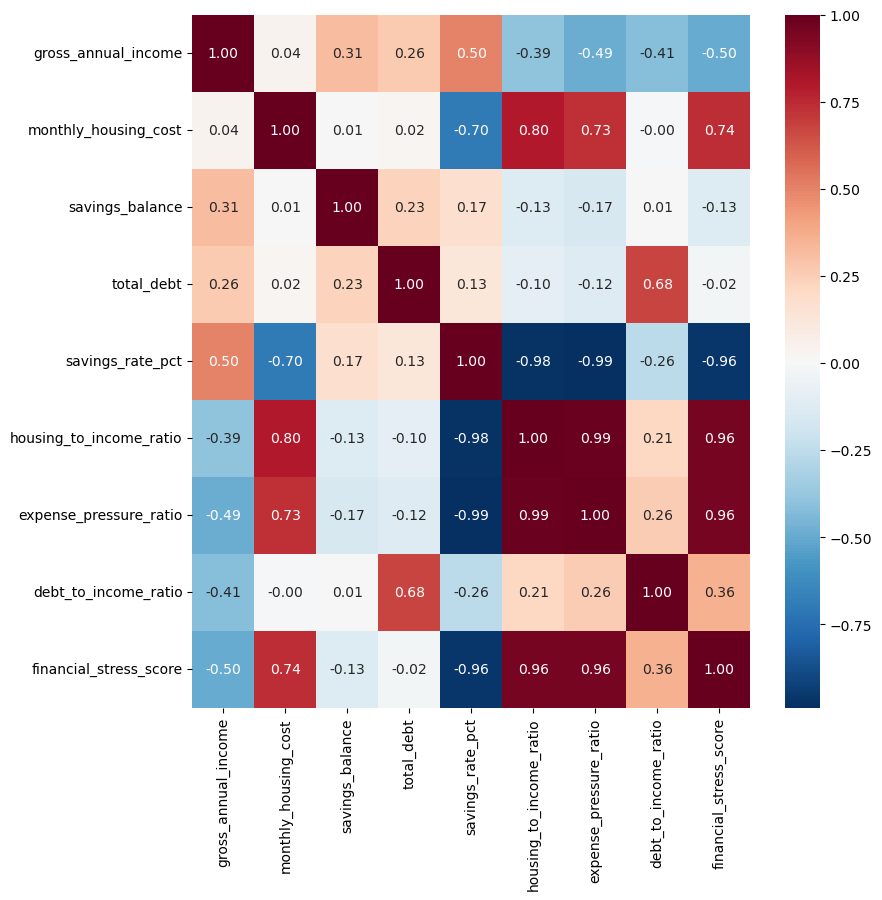

In [25]:
fig, ax = plt.subplots(figsize=(9,9))

sns.heatmap( 
            data= df.iloc[:, [10] + [11] + list(range(14,21))].corr(),
            cmap= 'RdBu_r', 
            fmt= '.2f', 
            annot= True); 



## Debt Load Analysis by Household Segment


**Business Question:** Which household segments carry the heaviest debt burden relative to income? How has
the debt-to-income ratio evolved across the rate hike period?

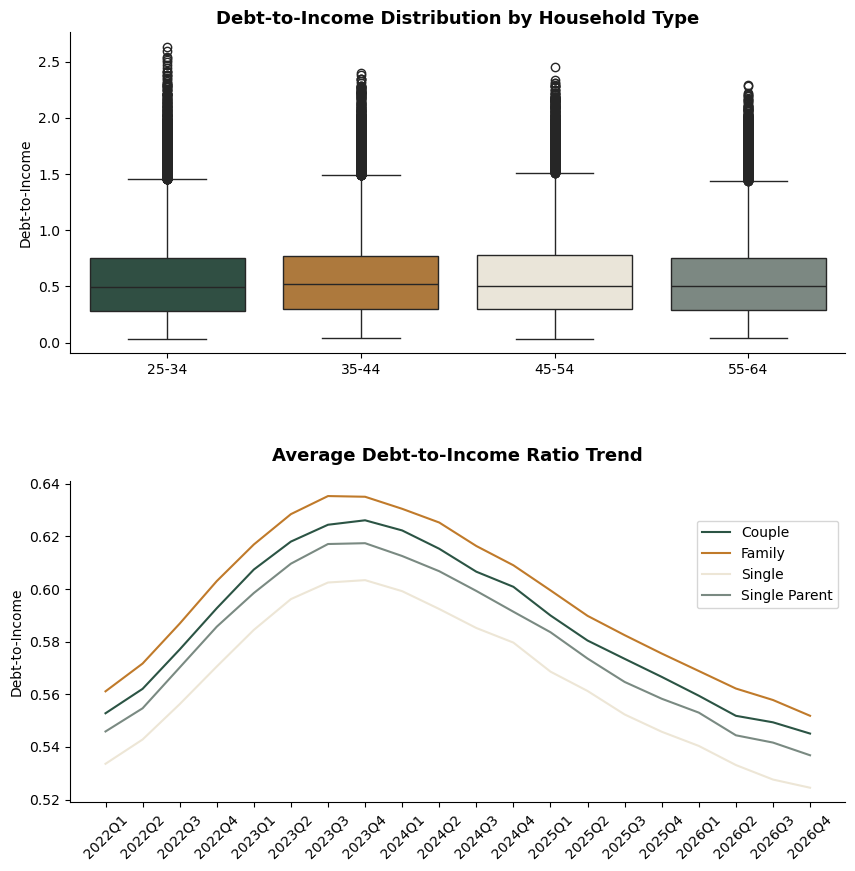

In [26]:
fig, ax = plt.subplots(2, 1, figsize=(10,10))


ax[0].set_title('Debt-to-Income Distribution by Household Type', fontweight='bold')

sns.boxplot(
            data= df, 
            x='age_bracket', 
            y='debt_to_income_ratio', 
            hue= 'age_bracket', 
            legend= False, 
            palette=['#2B5444', '#C07A2A', '#EDE6D6', '#7A8A82'],
            ax=ax[0]
)

ax[0].set_xlabel('')
ax[0].set_ylabel('Debt-to-Income')




plt.subplots_adjust(hspace= .4)




df_debt_to_income = df.groupby(['quarter', 'household_type'], observed=False).agg({'debt_to_income_ratio': 'mean'}).reset_index()

ax[1].set_title('Average Debt-to-Income Ratio Trend', fontweight='bold', pad=15)


sns.lineplot(
             data= df_debt_to_income, 
             x='quarter', 
             y='debt_to_income_ratio', 
             hue='household_type', 
             ax=ax[1], 
             palette=['#2B5444', '#C07A2A', '#EDE6D6', '#7A8A82']
)

ax[1].legend(bbox_to_anchor=(1,.9))

ax[1].set_xlabel('')
ax[1].set_ylabel('Debt-to-Income')
ax[1].tick_params(axis='x', rotation=45); 
 


Households with a debt-to-income ratio greater or equal than 1.5x are flagged as high-risk. 
This threshold indicates total non-mortgage debt is 1.5 times the household's 
annual gross income - a level associated with significant financial vulnerability, 
particularly under elevated interest rate conditions. 

In [27]:
df[df['housing_to_income_ratio'] >= 1.5]

,household_id,quarter,year,quarter_num,state,household_type,age_bracket,employment_type,n_income_earners,housing_status,...,monthly_housing_cost,monthly_utilities,monthly_insurance,savings_balance,total_debt,savings_rate_pct,housing_to_income_ratio,expense_pressure_ratio,debt_to_income_ratio,financial_stress_score
537,HH00538,2022Q1,2022,1,NSW,Single Parent,25-34,Part-time,1,Owner with Mortgage,...,4330.83,410.51,197.71,17133.41,55356.79,-50.0,1.5,1.8081,1.6888,85.21
606,HH00607,2022Q1,2022,1,NSW,Single Parent,45-54,Casual,1,Owner with Mortgage,...,4492.91,335.75,241.26,27082.01,6022.30,-50.0,1.5,1.8250,0.1807,78.18
1908,HH01909,2022Q1,2022,1,VIC,Single Parent,35-44,Casual,1,Owner with Mortgage,...,4421.02,452.15,257.61,36386.70,32873.00,-50.0,1.5,2.0000,1.2128,86.22
3461,HH03462,2022Q1,2022,1,NSW,Single Parent,25-34,Casual,1,Owner with Mortgage,...,4753.32,508.17,191.77,15182.50,17006.03,-50.0,1.5,1.9383,0.5037,80.32
3769,HH03770,2022Q1,2022,1,NSW,Single,25-34,Casual,1,Owner with Mortgage,...,4749.72,427.75,220.45,25055.80,48349.37,-50.0,1.5,1.9288,1.4397,84.95
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
98461,HH03462,2026Q4,2026,4,NSW,Single Parent,25-34,Casual,1,Owner with Mortgage,...,5159.18,593.89,233.89,11852.02,17214.88,-50.0,1.5,2.0000,0.5002,82.61
98769,HH03770,2026Q4,2026,4,NSW,Single,25-34,Casual,1,Owner with Mortgage,...,5209.49,474.81,268.80,21174.74,51961.70,-50.0,1.5,2.0000,1.5274,86.09
99354,HH04355,2026Q4,2026,4,VIC,Single,25-34,Casual,1,Owner with Mortgage,...,4261.88,458.82,218.27,9623.66,28895.15,-50.0,1.5,1.9459,0.9487,84.68
99586,HH04587,2026Q4,2026,4,VIC,Single,55-64,Casual,1,Owner with Mortgage,...,4669.32,426.05,267.43,37891.65,47425.44,-50.0,1.5,2.0000,1.5284,85.58


---
# 4. Predictive Projection — 2027/2029


## National Stress Score Projection

**Business Question:** Based on the 2022–2026 trend, where is the national average financial stress score
heading over the next three years? Is stress expected to continue declining or re-accelerate? 

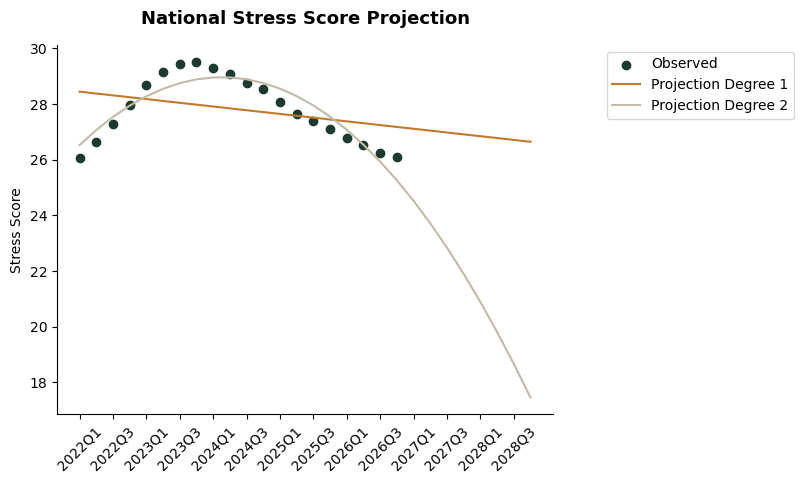

In [28]:
fig, ax = plt.subplots()

stress_by_quarter = df.groupby(['quarter']).agg(avg_stress_score = ('financial_stress_score', 'mean')).reset_index() 

observed_labels  = stress_by_quarter['quarter'].tolist()

projection_labels = ['2027Q1','2027Q2','2027Q3','2027Q4',
                     '2028Q1','2028Q2','2028Q3','2028Q4']

all_labels = observed_labels + projection_labels

x = np.arange(len(stress_by_quarter.index))
x_full = np.arange(len(stress_by_quarter.index) + 8)
y = stress_by_quarter['avg_stress_score'].values 

coeff_1d = np.polyfit(x, y, deg=1)
model1 = np.poly1d(coeff_1d)

coeff_2d = np.polyfit(x, y, deg=2) 
model2 = np.poly1d(coeff_2d)

y_fitted_1d = model1(x) 
y_proj_1d = model1(x_full)


y_fitted_2d = model2(x) 
y_proj_2d = model2(x_full)


ax.set_title('National Stress Score Projection', fontweight='bold', pad=15)


ax.scatter(
           x, 
           y,
           label='Observed', 
           color='#1C3A2F'
           
)


ax.plot(
        x_full, 
        y_proj_1d, 
        label='Projection Degree 1', 
        color='#C07A2A', 
        linewidth= 1.5
)


ax.plot(
        x_full, 
        y_proj_2d, 
        label='Projection Degree 2', 
        color='#C2BAA8', 
        linewidth= 1.5
)
 

ax.legend(bbox_to_anchor = (1.5,1))

ax.set_ylabel('Stress Score')
ax.set_xticks(ticks=np.arange(0, len(all_labels), 2) ,labels=all_labels[::2],rotation=45);
 

## State-Level Stress Projections

**Business Question:** Do different states show meaningfully different stress trajectories into 2027–2029? Which
state is projected to face the most persistent financial pressure?

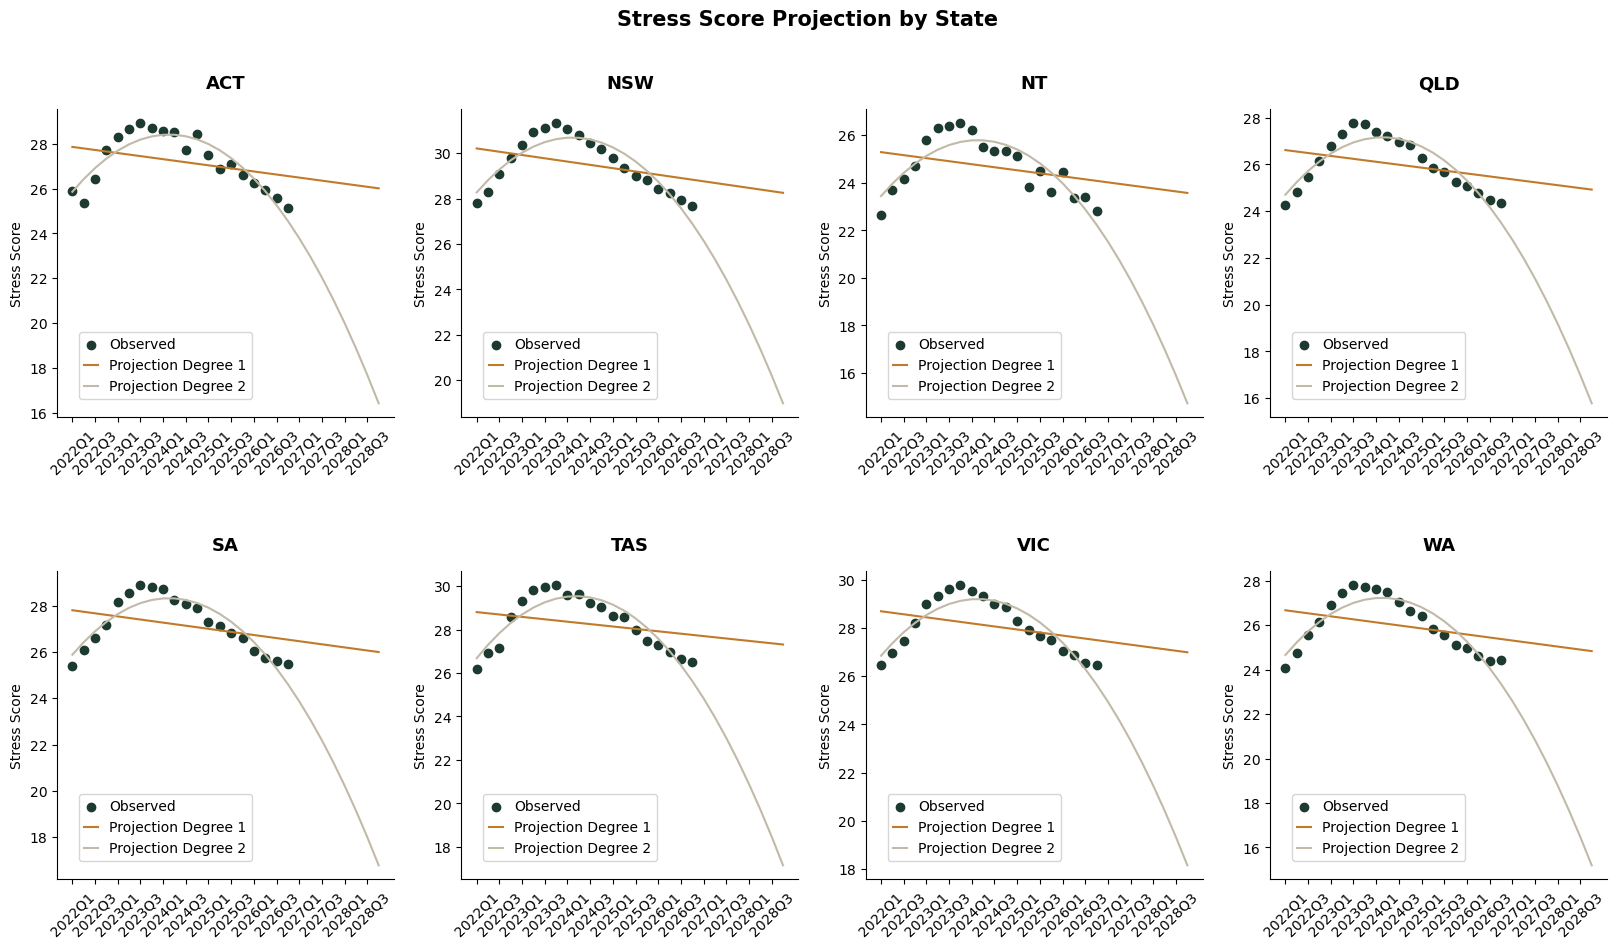

In [29]:
states_list = sorted(df['state'].unique())

fig, ax = plt.subplots(2,4, figsize=(20,10)) 

axes = ax.flatten() #converts 2D array into 1D 

fig.suptitle('Stress Score Projection by State', fontweight='bold', fontsize=15)


for i, state in enumerate(states_list): 

    stress_by_state = df[df['state'] == state].groupby(['quarter']).agg(avg_stress_score = ('financial_stress_score', 'mean')).reset_index()
    
    observed_labels  = stress_by_state['quarter'].tolist()
    
    projection_labels = ['2027Q1','2027Q2','2027Q3','2027Q4',
                         '2028Q1','2028Q2','2028Q3','2028Q4']
    
    all_labels = observed_labels + projection_labels
    
    x = np.arange(len(stress_by_state.index))
    x_full = np.arange(len(stress_by_state.index) + 8)
    y = stress_by_state['avg_stress_score'].values 
    
    coeff_1d = np.polyfit(x, y, deg=1)
    model1 = np.poly1d(coeff_1d)
    
    coeff_2d = np.polyfit(x, y, deg=2) 
    model2 = np.poly1d(coeff_2d)
    
    y_fitted_1d = model1(x) 
    y_proj_1d = model1(x_full)
    
    
    y_fitted_2d = model2(x) 
    y_proj_2d = model2(x_full)
    
    
    axes[i].set_title(f'{state}', fontweight='bold', pad=15)
    
    
    axes[i].scatter(
               x, 
               y,
               label='Observed', 
               color='#1C3A2F'
               
    )
    
    
    axes[i].plot(
            x_full, 
            y_proj_1d, 
            label='Projection Degree 1', 
            color='#C07A2A', 
            linewidth= 1.5
    )
    
    
    axes[i].plot(
            x_full, 
            y_proj_2d, 
            label='Projection Degree 2', 
            color='#C2BAA8', 
            linewidth= 1.5
    )
     
    
    axes[i].legend(bbox_to_anchor = (.6, .3), handlelength = 1, handleheight = .5)
    
    axes[i].set_ylabel('Stress Score')
    axes[i].set_xticks(ticks=np.arange(0, len(all_labels), 2) ,labels=all_labels[::2],rotation=45);
     
        

    
plt.subplots_adjust(hspace=0.5)
    
    
    
    

## High-Risk Segment Trajectory

**Business Question:** For the most financially stressed segment (Single Parent Renter in NSW), what
does the projected stress trajectory look like into 2029?

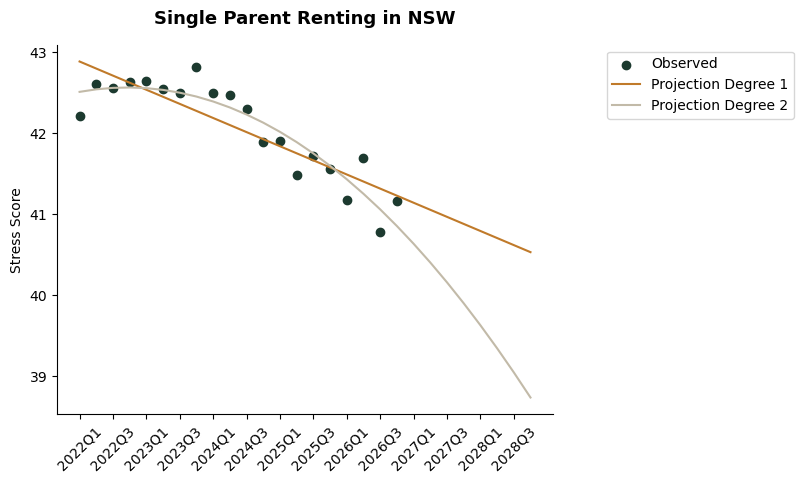

In [30]:

fig, ax = plt.subplots()

stress_by_quarter = df[(df['household_type'] == 'Single Parent') & (df['state'] == 'NSW') & (df['housing_status'] == 'Renter')].groupby(['quarter']).agg(avg_stress_score = ('financial_stress_score', 'mean')).reset_index() 

observed_labels  = stress_by_quarter['quarter'].tolist()

projection_labels = ['2027Q1','2027Q2','2027Q3','2027Q4',
                     '2028Q1','2028Q2','2028Q3','2028Q4']

all_labels = observed_labels + projection_labels

x = np.arange(len(stress_by_quarter.index))
x_full = np.arange(len(stress_by_quarter.index) + 8)
y = stress_by_quarter['avg_stress_score'].values 

coeff_1d = np.polyfit(x, y, deg=1)
model1 = np.poly1d(coeff_1d)

coeff_2d = np.polyfit(x, y, deg=2) 
model2 = np.poly1d(coeff_2d)

y_fitted_1d = model1(x) 
y_proj_1d = model1(x_full)


y_fitted_2d = model2(x) 
y_proj_2d = model2(x_full)


ax.set_title('Single Parent Renting in NSW', fontweight='bold', pad=15)


ax.scatter(
           x, 
           y,
           label='Observed', 
           color='#1C3A2F'
           
)


ax.plot(
        x_full, 
        y_proj_1d, 
        label='Projection Degree 1', 
        color='#C07A2A', 
        linewidth= 1.5
)


ax.plot(
        x_full, 
        y_proj_2d, 
        label='Projection Degree 2', 
        color='#C2BAA8', 
        linewidth= 1.5
)
 

ax.legend(bbox_to_anchor = (1.5,1))

ax.set_ylabel('Stress Score')
ax.set_xticks(ticks=np.arange(0, len(all_labels), 2) ,labels=all_labels[::2],rotation=45);
 

---
# 5. Business Insights & Recommendations


## Top 3 Stress Drivers — Ranked

The Correlation Matrix (Section 3) points clearly to three variables as the dominant drivers 
of financial stress across Australian households — not equally and not 
independently.


### 1. Housing-to-Income Ratio — The Primary Pressure Point

The single strongest predictor of financial stress in this dataset is how much 
of a household's monthly income is absorbed by housing costs. Mortgage holders 
in NSW reached a housing-to-income ratio above 70% at the cycle's peak in 
2023Q3 — meaning almost three quarters of gross monthly income was consumed by a single 
fixed obligation before a dollar was spent on anything else.

**So what:** For a bank or mortgage lender, this ratio is the earliest and most 
reliable signal of repayment stress. A household crossing the 30% threshold — 
the conventional housing stress benchmark in Australian policy — is statistically 
more likely to enter arrears within two to three quarters. 
Monitoring this ratio at a segment level, rather than waiting for missed payments, enables proactive intervention before defaults materialise.

---

### 2. Expense Pressure Ratio — The Compounding Force

While the `housing-to-income` ratio captures the fixed cost burden, the `expense_pressure_ratio` (`total_monthly_expenses` / `monthly_income`) captures the cumulative 
squeeze. When utilities and insurance are layered on top of housing, the most 
exposed segments — single parents and casual workers — saw their expense pressure 
ratio exceed 100% , meaning monthly obligations outstripped 
income entirely and households were forced to draw on savings or take on 
additional debt simply to stay current.

**So what:** For an insurer or financial services provider, the `expense_pressure_ratio` identifies households that are technically meeting their obligations but 
have no buffer. These households are one unexpected expense — a medical bill, a 
car repair — away from dissaving or default. Products designed around financial 
resilience (income protection, emergency savings accounts) are most commercially 
relevant precisely for this segment.

--- 

### 3. Monthly Housing Cost — The Rate Hike Transmission Mechanism

`monthly_housing_cost` appears as the third driver not because it is conceptually 
distinct from the `housing_to_income_ratio`, but because it captures the absolute 
dollar magnitude of the shock. The average monthly housing cost for mortgage 
holders rose from approximately 3500 AUD in 2022Q1 to 4500 AUD in 2023Q4 — an 
increase of 1000 AUD per month in four quarters, driven almost entirely by the RBA 
tightening cycle. Renters, by contrast, saw their average monthly cost remain 
broadly stable across the same period at approximately 2100 AUD.

**So what:** For a policy maker, this divergence is the central distributional 
finding of the dataset. The rate hike cycle imposed a highly concentrated cost 
on a specific sub-population — mortgage holders, disproportionately in NSW and 
VIC — while leaving renters relatively insulated from the immediate monetary 
transmission. Targeted relief measures (mortgage repayment deferrals) are more efficient than broad-based cost-of-living interventions 
precisely because the stress is not uniformly distributed.



## Executive Summary Narrative


### Situation
Between Q1 2022 and Q4 2026, the average Financial Stress Score across 5,000 
Australian households rose from 26 to a peak of 30 in Q3 2023, before 
partially recovering to by Q4 2026. The primary driver was the RBA rate 
hike cycle, which pushed average monthly housing costs for mortgage holders 
from 3 300 AUD in Q1 2022 to 4 500 AUD by Q4 2023 — an increase of 1 200 AUD/month. 
Renters remained broadly insulated, with average monthly 
costs stable at approximately 2 100 AUD across the same period.


### Complication
The national average conceals a severe distributional imbalance. Single parents 
with a mortgage in NSW reached a Financial Stress Score of 62/100 at peak — 34 
points above the national average of 28 — with a housing-to-income ratio 
of 1.5×. Casual workers saw their savings rate turn negative as early as 
Q1 2022 and never recover, while 8% of households nationally were dissaving 
on average across the observed period. The moderate stress threshold of 30 was 
breached nationally in Q3 2023, with 42% of all households crossing into 
moderate-to-high stress territory simultaneously.


### Recommendation
Broad-based cost-of-living interventions are inefficient given the concentration 
of stress. Three segments warrant immediate prioritisation: single parents with 
a mortgage in NSW, casual workers and young families aged 25–34 
carrying a debt-to-income ratio above 1.5×. For financial services providers, the priority is unambiguous: engage households 
whose housing costs exceed 30% of monthly income at the first sign of ratio 
deterioration — well before repayment stress occurs.